> **Camera-ready note.** The kinetic-energy *table* is produced by
> `waveletflux.analysis.physics.ke_table` via `scripts/reproduce_tables.py`
> (`artifacts/tables/tex/R2_ke_mae.tex`). This notebook is kept for the physics
> *figures*. Its in-notebook table reproduces the rebuttal numbers, which used
> exclusive horizon bounds and **WDNO db6**; the camera-ready table uses the
> paper's inclusive bounds and WDNO db2 (as everywhere else in the paper).

# Physics-consistency figures

Same infrastructure as `figures.ipynb`: shared `MODEL_REGISTRY` (colors, labels,
line styles, legend grouping), multi-PDE auto-discovery of `*_metrics.csv`
files (seeds parsed from filenames / the `seed` column), LaTeX fonts.

**Seed convention used throughout**
- *seed-resolved* plots: one line per seed, drawn in progressively lighter
  **shades of the model's registry color**;
- *seed-averaged* plots: trajectories are averaged **within** each seed first,
  then the line is the mean across seeds in the **main registry color**, with a
  $\pm 1$ sd band across seeds (models with a single seed get a line, no band).

Adding a PDE later = drop its `*_metrics.csv` files into
`experiments/<pde>/metrics/` and (if new) add the PDE to `PDEs`,
`PDE_LABELS`, `pde_xlims`, `horizon_fn`, `DATASET_METRIC`. Nothing else.

In [1]:
from matplotlib.ticker import MaxNLocator
import matplotlib.patches as mpatches
from matplotlib.lines import Line2D
import matplotlib.colors as mcolors
import matplotlib.lines as mlines
import matplotlib.pyplot as plt
from pathlib import Path
import seaborn as sns          # only for optional exploration; NEVER call
import pandas as pd            # sns.set_theme() here — it clobbers the LaTeX rc
import numpy as np
import shutil
import glob
import math
import sys
import re

rc = {
    "axes.axisbelow": True,
    "axes.linewidth": 1.0,
    "axes.labelsize": "x-small",
    "axes.titlesize": "x-small",
    "figure.dpi": 150,
    "figure.figsize": (3.2, 3.2),
    "font.size": 12.0,
    "legend.fontsize": "xx-small",
    "lines.linewidth": 1.0,
    "savefig.transparent": True,
    "xtick.labelsize": "xx-small",
    "xtick.major.width": 1.0,
    "ytick.labelsize": "xx-small",
    "ytick.major.width": 1.0,
    "font.family": ["serif"],
    "text.usetex": shutil.which("latex") is not None,   # same LaTeX font as figures.ipynb
    "text.latex.preamble": r"\usepackage{amsfonts}",
}
plt.rcParams.update(rc)

from pathlib import Path as _Path
PROJECT_ROOT = str(next(p for p in [_Path.cwd(), *_Path.cwd().parents] if (p / "pyproject.toml").exists()))  # repo root, works on laptop and cluster
sys.path.insert(0, PROJECT_ROOT)

FIG_DIR   = Path(PROJECT_ROOT) / "figures"
SAVE_FIGS = False
FIG_DIR.mkdir(parents=True, exist_ok=True)

In [2]:
#trl = pd.read_csv('/Users/gabrieleaccarino/Workspace/waveletflux/experiments/turbulent_radiative_layer_2D/metrics/WaveletFlow_1scale_db2_v4.0_nsampling50_nens8_turbulent_radiative_layer_2D_stats.csv')
#rbl = pd.read_csv('/Users/gabrieleaccarino/Workspace/waveletflux/experiments/rayleigh_benard/metrics/WaveletFlow_1scale_db2_v4.0_nsampling50_nens8_rayleigh_benard_stats.csv')
#am = pd.read_csv('/Users/gabrieleaccarino/Workspace/waveletflux/experiments/active_matter/metrics/WaveletFlow_1scale_db2_v4.0_nsampling50_nens8_active_matter_psd.csv')

#print(f'TRL: {trl.field.unique()}')
#print(f'RBL: {rbl.field.unique()}')
#print(f'AM: {am.field.unique()}')

# Model Registry — identical to `figures.ipynb`

Copy of the registry so colors/labels/line styles match every other figure. `FourierFlow_16modes_v4.0` added (it was referenced in the old physics notebook but missing from the registry).

In [3]:
def rgb_to_hex(r, g, b):
    return f"#{r:02x}{g:02x}{b:02x}"

MODEL_REGISTRY = {
    "WaveletFlow_1scale_haar_v4.0": dict(
        label  = "WFM 1-scale haar (ours)",
        color  = rgb_to_hex(55, 82, 64),
        dash   = (1, 0), lw = 2.5,
        groups = {"ours"},
        legend_group = "WFM 1-scale (ours)", legend_rank = 0,
    ),
    "WaveletFlow_1scale_db2_v4.0": dict(
        label  = "WFM 1-scale db2 (ours)",
        color  = rgb_to_hex(55, 82, 64),
        dash   = (1, 0), lw = 2.5,
        groups = {"ours"},
        legend_group = "WFM 1-scale (ours)", legend_rank = 0,
    ),
    "WaveletFlow_1scale_db4_v4.0": dict(
        label  = "WFM 1-scale db4 (ours)",
        color  = rgb_to_hex(55, 82, 64),
        dash   = (1, 0), lw = 2.5,
        groups = {"ours"},
        legend_group = "WFM 1-scale (ours)", legend_rank = 0,
    ),
    "WaveletFlow_1scale_db6_v4.0": dict(
        label  = "WFM 1-scale db6 (ours)",
        color  = rgb_to_hex(55, 82, 64),
        dash   = (1, 0), lw = 2.5,
        groups = {"ours"},
        legend_group = "WFM 1-scale (ours)", legend_rank = 0,
    ),
    "WaveletFlow_3scales_haar_v4.0": dict(
        label  = "WFM 3-scale haar (ours)",
        color  = rgb_to_hex(117, 176, 138),
        dash   = (1, 0), lw = 2.5,
        groups = {"ours"},
        legend_group = "WFM 3-scale (ours)", legend_rank = 1,
    ),
    "WaveletFlow_3scales_db2_v4.0": dict(
        label  = "WFM 3-scale db2 (ours)",
        color  = rgb_to_hex(117, 176, 138),
        dash   = (1, 0), lw = 2.5,
        groups = {"ours"},
        legend_group = "WFM 3-scale (ours)", legend_rank = 1,
    ),
    "WaveletFlow_3scales_db4_v4.0": dict(
        label  = "WFM 3-scale db4 (ours)",
        color  = rgb_to_hex(117, 176, 138),
        dash   = (1, 0), lw = 2.5,
        groups = {"ours"},
        legend_group = "WFM 3-scale (ours)", legend_rank = 1,
    ),
    "WaveletFlow_3scales_db6_v4.0": dict(
        label  = "WFM 3-scale db6 (ours)",
        color  = rgb_to_hex(117, 176, 138),
        dash   = (1, 0), lw = 2.5,
        groups = {"ours"},
        legend_group = "WFM 3-scale (ours)", legend_rank = 1,
    ),
    "FM_data_space_v4.0": dict(
        label  = r"FM$_{pixel}$",
        color  = rgb_to_hex(176, 176, 176),
        dash   = (1, 0), lw = 1.8,
        groups = {"generative"}, legend_rank = -1,
    ),
    #"FourierFlow_16modes_v4.0": dict(
    #    label  = r"FM$_{fourier}$",
    #    color  = rgb_to_hex(143, 94, 106),
    #    dash   = (1, 0), lw = 1.8,
    #    groups = {"generative"}, legend_rank = 3,
    #),
    "FourierFlow_32modes_v4.0": dict(                   # ← added: used by the
        label  = r"FM$_{fourier}$",                     #   physics CSVs
        color  = rgb_to_hex(171, 122, 134),
        dash   = (1, 0), lw = 1.8,
        groups = {"generative"}, legend_rank = 3,
    ),
    "WDNO": dict(
        label  = "WDNO",
        color  = rgb_to_hex(191, 134, 148),
        dash   = (1, 0), lw = 1.8,
        groups = {"generative"}, legend_rank = 4,
    ),
    "WNO_3scales_db2": dict(
        label  = "WNO",
        color  = rgb_to_hex(176, 136, 84),
        dash   = (1, 0), lw = 1.8,
        groups = {"deterministic"}, legend_rank = 5,
    ),
    "FNO": dict(
        label  = "FNO",
        color  = rgb_to_hex(208, 169, 110),
        dash   = (1, 0), lw = 1.8,
        groups = {"deterministic"}, legend_rank = 6,
    ),
    "TFNO": dict(
        label  = "TFNO",
        color  = rgb_to_hex(236, 227, 163),
        dash   = (1, 0), lw = 1.8,
        groups = {"deterministic"}, legend_rank = 7,
    ),
}

PDEs = ['turbulent_radiative_layer_2D', 'rayleigh_benard', 'active_matter']

# which WFM wavelet wins per PDE (same as figures.ipynb)
pde_best_model = {
    "turbulent_radiative_layer_2D": ["WaveletFlow_1scale_haar_v4.0", "WaveletFlow_3scales_haar_v4.0"],
    "rayleigh_benard":              ["WaveletFlow_1scale_db4_v4.0", "WaveletFlow_3scales_db4_v4.0"],
    "active_matter":                ["WaveletFlow_1scale_haar_v4.0", "WaveletFlow_3scales_db2_v4.0"],
}

model_checklist = [m for m in MODEL_REGISTRY]

palette     = {m: MODEL_REGISTRY[m]["color"] for m in model_checklist}
dashes      = {m: MODEL_REGISTRY[m]["dash"]  for m in model_checklist}
labels      = {m: MODEL_REGISTRY[m]["label"] for m in model_checklist}
linewidths  = {m: MODEL_REGISTRY[m]["lw"]    for m in model_checklist}

det_models  = [m for m in model_checklist if "deterministic" in MODEL_REGISTRY[m]["groups"]]
gen_models  = [m for m in model_checklist if "generative"    in MODEL_REGISTRY[m]["groups"]]
ours_models = [m for m in model_checklist if "ours"          in MODEL_REGISTRY[m]["groups"]]

color_to_model = {v: k for k, v in palette.items()}

GT_LABEL             = "Ground-truth"
palette[GT_LABEL]    = "#222222"
dashes[GT_LABEL]     = (4, 2)
labels[GT_LABEL]     = "Ground-truth"
linewidths[GT_LABEL] = 1.8

def model_type(model):
    groups = MODEL_REGISTRY.get(model, {}).get("groups", set())
    if "ours"       in groups: return "ours"
    if "generative" in groups: return "generative"
    return "deterministic"

def legend_order(model_subset):
    registry_keys = list(MODEL_REGISTRY.keys())
    def rank(m):
        return (MODEL_REGISTRY[m].get("legend_rank", 999),
                registry_keys.index(m) if m in registry_keys else 999)
    return sorted(model_subset, key=rank)

# ══════════════════════════════════════════════════════════════════════════════
# FAMILIES — one identity across PDEs even when the wavelet basis differs.
# "WFM 3-scale" is haar on TRL, db4 on RB, db2 on AM: three registry KEYS that
# must appear as ONE row / ONE line / ONE colour / ONE label.
# ══════════════════════════════════════════════════════════════════════════════
FAMILY_REGISTRY = {
    "WFM_1scale": dict(label="WFM 1-scale (ours)", color=rgb_to_hex(55, 82, 64), dash=(1, 0), lw=2.5, groups={"ours"}, legend_rank=0),
    "WFM_3scale": dict(label="WFM 3-scale (ours)", color=rgb_to_hex(117, 176, 138), dash=(1, 0), lw=2.5, groups={"ours"}, legend_rank=1),
    "FM_pixel":   dict(label=r"FM$_{pixel}$",   color=rgb_to_hex(176, 176, 176), dash=(1, 0), lw=1.8, groups={"generative"}, legend_rank=2),
    "FM_fourier": dict(label=r"FM$_{fourier}$", color=rgb_to_hex(171, 122, 134), dash=(1, 0), lw=1.8, groups={"generative"}, legend_rank=3),
    "WDNO": dict(label="WDNO", color=rgb_to_hex(191, 134, 148), dash=(1, 0), lw=1.8, groups={"generative"}, legend_rank=4),
    "WNO":  dict(label="WNO",  color=rgb_to_hex(176, 136, 84),  dash=(1, 0), lw=1.8, groups={"deterministic"}, legend_rank=5),
    "FNO":  dict(label="FNO",  color=rgb_to_hex(208, 169, 110), dash=(1, 0), lw=1.8, groups={"deterministic"}, legend_rank=6),
    "TFNO": dict(label="TFNO", color=rgb_to_hex(236, 227, 163), dash=(1, 0), lw=1.8, groups={"deterministic"}, legend_rank=7),
}

def _infer_family(key):
    if key.startswith("WaveletFlow_1scale"):  return "WFM_1scale"
    if key.startswith("WaveletFlow_3scales"): return "WFM_3scale"
    if key.startswith("FM_data_space"):       return "FM_pixel"
    if key.startswith("FourierFlow"):         return "FM_fourier"
    for fam in ("WDNO", "WNO", "FNO", "TFNO"):
        if key.startswith(fam): return fam
    return key

KEY_TO_FAMILY  = {k: _infer_family(k) for k in MODEL_REGISTRY}

fam_palette    = {f: FAMILY_REGISTRY[f]["color"] for f in FAMILY_REGISTRY}
fam_dashes     = {f: FAMILY_REGISTRY[f]["dash"]  for f in FAMILY_REGISTRY}
fam_labels     = {f: FAMILY_REGISTRY[f]["label"] for f in FAMILY_REGISTRY}
fam_linewidths = {f: FAMILY_REGISTRY[f]["lw"]    for f in FAMILY_REGISTRY}

def family_type(fam):
    groups = FAMILY_REGISTRY.get(fam, {}).get("groups", set())
    if "ours"       in groups: return "ours"
    if "generative" in groups: return "generative"
    return "deterministic"

def family_order(fams):
    keys = list(FAMILY_REGISTRY)
    return sorted(fams, key=lambda f: (FAMILY_REGISTRY.get(f, {}).get("legend_rank", 999),
                                       keys.index(f) if f in keys else 999))

fam_ours = [f for f in FAMILY_REGISTRY if "ours" in FAMILY_REGISTRY[f]["groups"]]

# The concrete key that REPRESENTS a family for a given PDE (winner from
# pde_best_model if pinned, else whichever key of that family is present).
def canonical_key(pde, family, present_keys):
    for k in pde_best_model.get(pde, []):
        if KEY_TO_FAMILY.get(k) == family and k in present_keys:
            return k
    cand = [k for k in present_keys if KEY_TO_FAMILY.get(k) == family]
    return cand[0] if cand else None


# Load metrics files

Auto-discovers every `*_metrics.csv` under `experiments/<pde>/metrics/` for each registry model, across all seeds. Seed comes from the CSV's `seed` column (stamped by `inference.py`), with a filename-regex fallback. `_global_` rows carry the coupled diagnostics; the rest are per-field.

In [4]:
GLOBAL_FIELD_LABEL = "_global_"
METRICS_SUBDIR     = "metrics"          # change to "results" if reading in place
SEED_RE            = re.compile(r"seed(\d+)")

def enrich_metrics(df, stem, model_name, pde):
    parts     = stem.split('_')
    nsampling = next((p.replace('nsampling', '') for p in parts if p.startswith('nsampling')), None)
    nens      = next((p.replace('nens',      '') for p in parts if p.startswith('nens')),      None)
    df['model'] = model_name                       # force registry key
    df['family'] = KEY_TO_FAMILY.get(model_name, model_name)  # cross-PDE identity
    if 'seed' not in df.columns or df['seed'].isna().all():
        m = SEED_RE.search(stem)
        df['seed'] = int(m.group(1)) if m else -1
    df['seed']      = df['seed'].astype(int)
    df['source']    = stem
    df['pde']       = pde
    df['nsampling'] = int(nsampling) if nsampling else None
    df['nens']      = int(nens)      if nens      else None
    return df

dfs_metrics = []
for pde in PDEs:
    print(f"\n{'='*60}\nLoading PDE: {pde}\n{'='*60}")
    for model in model_checklist:
        pattern = f'{PROJECT_ROOT}/experiments/{pde}/{METRICS_SUBDIR}/{model}*_metrics.csv'
        files   = sorted(glob.glob(pattern))
        if not files:
            print(f"  [    ] no metrics for '{model}'")
            continue
        for fpath in files:
            try:
                d    = pd.read_csv(fpath)
                stem = Path(fpath).stem
                d    = enrich_metrics(d, stem, model, pde)
                dfs_metrics.append(d)
                print(f"  [OK  ] {d.shape} seed={d['seed'].iloc[0]:<4d} | {Path(fpath).name}")
            except Exception as e:
                print(f"  [ERR ] {fpath}: {e}")

DEDUP_EXCLUDE = {'source', 'nsampling', 'nens'}
if dfs_metrics:
    metrics_df = pd.concat(dfs_metrics, ignore_index=True)
    metrics_df = metrics_df.drop_duplicates(
        subset=[c for c in metrics_df.columns if c not in DEDUP_EXCLUDE])
else:
    metrics_df = pd.DataFrame()
    print("[WARN] no metrics loaded")

pde_present = [p for p in PDEs if not metrics_df.empty and p in set(metrics_df['pde'])]
print(f"\nmetrics_df: {metrics_df.shape} | PDEs present: {pde_present}")
if not metrics_df.empty:
    print(metrics_df.groupby(['pde','model'])['seed']
          .unique().apply(sorted).rename('seeds').to_string())

# ── AUDIT: which concrete key represents each (pde, family)? ─────────────────
if not metrics_df.empty:
    print("\n[family audit] representative key per (pde, family):")
    for pde in [p for p in PDEs if p in set(metrics_df['pde'])]:
        keys = set(metrics_df.loc[metrics_df.pde == pde, 'model'])
        for fam in family_order({KEY_TO_FAMILY.get(k, k) for k in keys}):
            ck = canonical_key(pde, fam, keys)
            same_fam = sorted(k for k in keys if KEY_TO_FAMILY.get(k) == fam)
            flag = "" if len(same_fam) <= 1 else f"  (of {len(same_fam)}: {same_fam})"
            print(f"    {pde:30s} {fam:12s} -> {ck}{flag}")



Loading PDE: turbulent_radiative_layer_2D
  [OK  ] (4365, 66) seed=168  | WaveletFlow_1scale_haar_v4.0_nsampling50_nens8_seed168_turbulent_radiative_layer_2D_metrics.csv
  [OK  ] (4365, 66) seed=42   | WaveletFlow_1scale_haar_v4.0_nsampling50_nens8_seed42_turbulent_radiative_layer_2D_metrics.csv
  [OK  ] (4365, 66) seed=84   | WaveletFlow_1scale_haar_v4.0_nsampling50_nens8_seed84_turbulent_radiative_layer_2D_metrics.csv
  [OK  ] (4365, 66) seed=168  | WaveletFlow_1scale_db2_v4.0_nsampling50_nens8_seed168_turbulent_radiative_layer_2D_metrics.csv
  [OK  ] (4365, 66) seed=42   | WaveletFlow_1scale_db2_v4.0_nsampling50_nens8_seed42_turbulent_radiative_layer_2D_metrics.csv
  [OK  ] (4365, 66) seed=84   | WaveletFlow_1scale_db2_v4.0_nsampling50_nens8_seed84_turbulent_radiative_layer_2D_metrics.csv
  [OK  ] (4365, 66) seed=168  | WaveletFlow_1scale_db4_v4.0_nsampling50_nens8_seed168_turbulent_radiative_layer_2D_metrics.csv
  [OK  ] (4365, 66) seed=42   | WaveletFlow_1scale_db4_v4.0_nsampling

# Config: PDE labels, axis limits, horizons, metric resolution

`horizon_fn` mirrors `figures.ipynb`. `conservation_col` resolves the constraint-residual column per PDE (`continuity_ratio` for compressible TRL, `divnorm_ratio` for incompressible RB/AM). `DATASET_METRIC` maps each PDE to its system-specific scientific observable.

In [5]:
PDE_LABELS = {
    'turbulent_radiative_layer_2D' : 'Turbulent Radiative Layer 2D',
    'rayleigh_benard'              : 'Rayleigh-Bénard' if rc["text.usetex"] else 'Rayleigh-Bénard',
    'active_matter'                : 'Active Matter',
}

pde_xlims = {
    'turbulent_radiative_layer_2D' : (-5, 100),
    'rayleigh_benard'              : (-5, 200),
    'active_matter'                : (-5, 80),
}

def horizon_rayleigh_benard(t):
    return "01:32" if t < 32 else ("33:64" if t < 64 else "65:196")
def horizon_active_matter(t):
    return "01:16" if t < 16 else ("17:32" if t < 32 else "33:77")
def horizon_turbulent_radiative_layer_2D(t):
    return "01:32" if t < 32 else ("33:64" if t < 64 else "65:97")

horizon_fn = {
    'turbulent_radiative_layer_2D': horizon_turbulent_radiative_layer_2D,
    'rayleigh_benard':              horizon_rayleigh_benard,
    'active_matter':                horizon_active_matter,
}

aggregate_mode = "mean"
def aggregate(x):
    return np.nanmean(x) if "mean" in aggregate_mode else np.nanmedian(x)

if not metrics_df.empty:
    metrics_df['step'] = metrics_df['step'] + 1          # 1-based, as in figures.ipynb
    metrics_df["horizon"] = pd.Series(pd.NA, index=metrics_df.index, dtype="object")
    for pde, fn in horizon_fn.items():
        mask = metrics_df["pde"] == pde
        metrics_df.loc[mask, "horizon"] = metrics_df.loc[mask, "step"].apply(fn)
    metrics_df["model_type"] = metrics_df["model"].apply(model_type)

    g  = metrics_df[metrics_df["field"] == GLOBAL_FIELD_LABEL].copy()
    pf = metrics_df[metrics_df["field"] != GLOBAL_FIELD_LABEL].copy()
else:
    g = pf = pd.DataFrame()

# ── column resolvers (robust to per-PDE differences) ─────────────────────────
CONS_CANDIDATES = ["continuity_ratio", "divnorm_ratio"]

def conservation_col(pde):
    sub = g[g["pde"] == pde]
    for c in CONS_CANDIDATES:
        if c in sub.columns and sub[c].notna().any():
            return c
    return None

DATASET_METRIC = {          # (column, LaTeX label) — the system-specific observable
    'turbulent_radiative_layer_2D': ("massflux_bias", r"$\langle \rho u_y \rangle$ rel.\ bias"),
    'rayleigh_benard':              ("nusselt_bias",  r"$\mathrm{Nu}$ rel.\ bias"),
    'active_matter':                ("nematic_bias",  r"$S$ rel.\ bias"),
}

def models_in(pde, frame=None):
    frame = g if frame is None else frame
    present = set(frame.loc[frame["pde"] == pde, "model"])
    return [m for m in model_checklist if m in present]

TEXT_WIDTH = 12.0
ROW_HEIGHT = 2.8
LEGEND_LW  = 1.8

# ── Collapse to ONE representative key per (pde, family) ─────────────────────
# This is the guard against accidentally averaging different checkpoints of the
# same family: only the canonical key survives, so a later groupby on "family"
# has exactly one key per (pde, family, seed, step).
def family_frame(frame):
    if frame.empty:
        return frame
    keep = set()
    for pde in frame["pde"].unique():
        present = set(frame.loc[frame.pde == pde, "model"])
        for fam in {KEY_TO_FAMILY.get(k, k) for k in present}:
            ck = canonical_key(pde, fam, present)
            if ck is not None:
                keep.add((pde, ck))
    idx = list(zip(frame["pde"], frame["model"]))
    mask = np.array([pair in keep for pair in idx])
    return frame[mask].copy()

def families_in(pde, frame=None):
    frame = g if frame is None else frame
    present = set(frame.loc[frame["pde"] == pde, "family"])
    return [f for f in family_order(present)]


# Stable renormalization (no cropping)

The stored `*_mae` / `*_bias` columns are relative to the **instantaneous** truth, which is near zero during RB spin-up ($E_k^{\rm true}\sim10^{-10}$ vs a sampler noise floor $\sim10^{-6}$), inflating the ratio to $10^4$. Instead of masking those steps, we renormalize: the relative columns are exact ratios, so multiplying back by $|Q_{\rm true}(t)|$ recovers the absolute error exactly, and dividing by the **trajectory-time-mean** $\overline{|Q_{\rm true}|}$ gives

$$\widetilde{\mathrm{mae}}_Q(t)=\frac{\frac1M\sum_m|Q(x_m^t)-Q(x^t)|}{\overline{|Q_{\rm true}|}^{\,\rm traj}},\qquad\widetilde{\mathrm{bias}}_Q(t)=\frac{|\frac1M\sum_mQ(x_m^t)-Q(x^t)|}{\overline{|Q_{\rm true}|}^{\,\rm traj}}.$$

Every step is kept; the denominator is strictly positive and identical for all models/seeds (truth-only). For TRL/AM, whose true quantities are roughly stationary, $\widetilde{\cdot}\approx$ the original columns, so this is a **uniform** redefinition across systems, not an RB special case. Paper wording: *“relative errors are normalized by the trajectory-mean true value.”* New columns get the `_tm` suffix (`ke_mae_tm`, …).

In [6]:
# ── Stable renormalization: *_tm columns (trajectory-time-mean denominator) ──
# The stored relative metrics divide by |Q_true(t)|; we rebuild the absolute
# error exactly (rel * |Q_true|) and re-divide by the per-trajectory time-mean
# of |Q_true| — strictly positive, truth-only, identical for every model/seed.
RENORM_BASES = ["ke", "enstrophy", "massflux", "nusselt", "nematic", "gradsq"]                     # any base with a *_true column

def add_tm_metrics(df):
    """Add {base}_mae_tm / {base}_bias_tm for every base whose {base}_true,
    and at least one of {base}_mae / {base}_bias, are present."""
    if df.empty:
        return df
    df = df.copy()
    per_field = "field" in df.columns and (df["field"] != GLOBAL_FIELD_LABEL).any()
    key = ["pde", "traj"] + (["field"] if per_field else [])
    for base in RENORM_BASES:
        t = f"{base}_true"
        if t not in df.columns or df[t].notna().sum() == 0:
            continue
        # truth is identical across models/seeds; dedup before time-averaging
        truth = (df.dropna(subset=[t])
                   .groupby(key + ["step"], as_index=False)[t].mean())
        denom = (truth.assign(_a=truth[t].abs())
                      .groupby(key, as_index=False)["_a"].mean()
                      .rename(columns={"_a": f"_{base}_den"}))
        df = df.merge(denom, on=key, how="left")
        for stat in ("mae", "bias"):
            c = f"{base}_{stat}"
            if c in df.columns:
                df[f"{c}_tm"] = df[c] * df[t].abs() / df[f"_{base}_den"]
        df = df.drop(columns=[f"_{base}_den"])
    return df

g_phys  = add_tm_metrics(g)      # ← plots/tables read the *_tm columns from here
pf_phys = add_tm_metrics(pf)

# quick report: how much the redefinition matters per PDE (ratio ≈ 1 ⇒ negligible)
for pde in pde_present:
    sub = g_phys[(g_phys["pde"] == pde)].dropna(subset=["ke_mae", "ke_mae_tm"])
    if len(sub):
        print(f"{pde:32s} ke_mae max: {sub['ke_mae'].max():10.3g}  "
              f"-> ke_mae_tm max: {sub['ke_mae_tm'].max():10.3g}")


turbulent_radiative_layer_2D     ke_mae max:       1.33  -> ke_mae_tm max:       1.33
rayleigh_benard                  ke_mae max:   1.12e+08  -> ke_mae_tm max:       27.9
active_matter                    ke_mae max:   4.25e+05  -> ke_mae_tm max:       30.6


# Helpers: seed shading, seed-aware aggregation, panels, shared legend

`draw_metric(..., mode="seed_avg")` averages trajectories **within** each seed, then draws the across-seed mean in the model's main color with a $\pm 1$ sd band. `mode="per_seed"` draws one line per seed in lighter shades of the same color (darkest = lowest seed).

In [7]:
def lighten(color, frac):
    """Blend a color toward white; frac=0 -> original, frac=1 -> white."""
    rgb = np.array(mcolors.to_rgb(color))
    return tuple(rgb + (1.0 - rgb) * frac)

def seed_shade_map(family, seeds, max_lighten=0.55):
    seeds = sorted(int(s) for s in set(seeds))
    fracs = np.linspace(0.0, max_lighten, len(seeds)) if len(seeds) > 1 else [0.0]
    return {s: lighten(fam_palette[family], f) for s, f in zip(seeds, fracs)}

def seed_mean(df, metric, by="family", extra=()):
    """One value per (pde, <by>, seed, step[, extra]): mean over trajectories.
    Averaging trajectories first keeps seeds as the replication unit."""
    keys = ["pde", by, "seed", "step", *extra]
    return (df.dropna(subset=[metric])
              .groupby(keys, as_index=False)[metric].mean())

def draw_metric(ax, df, pde, metric, families_shown, mode="seed_avg",
                logy=False, ref=None, band_alpha=0.18):
    """One metric-vs-lead-time panel, ONE line per FAMILY (canonical key only).

    df is expected to be already collapsed by family_frame(), so each
    (pde, family, seed, step) maps to a single checkpoint. A guard below makes
    accidental multi-key pooling loud instead of silent.
    """
    if metric not in df.columns:
        ax.set_visible(False); return
    dpde = df[df["pde"] == pde]

    # GUARD: no family may carry >1 concrete key for this PDE (would pool models)
    dup = (dpde.groupby("family")["model"].nunique())
    bad = dup[dup > 1]
    if len(bad):
        raise ValueError(f"[{pde}] families with >1 key (would average distinct "
                         f"models): {dict(bad)}. Pass family_frame(g_phys).")

    sc = seed_mean(dpde, metric, by="family")
    for fam in families_shown:
        sub = sc[sc["family"] == fam]
        if sub.empty:
            continue
        if mode == "per_seed":
            smap = seed_shade_map(fam, sub["seed"].unique())
            for s, ss in sub.groupby("seed"):
                ax.plot(ss["step"], ss[metric], color=smap[int(s)],
                        dashes=fam_dashes[fam],
                        lw=max(fam_linewidths[fam] - 0.7, 0.9), alpha=0.95, zorder=3)
        else:  # seed_avg — line = mean across seeds, band = min-max envelope
            agg = (sub.groupby("step")[metric]
                      .agg(mean="mean", lo="min", hi="max", n="count").reset_index())
            ax.plot(agg["step"], agg["mean"], color=fam_palette[fam],
                    dashes=fam_dashes[fam], lw=fam_linewidths[fam], zorder=3)
            multi = agg["n"] > 1
            if multi.any():
                a = agg[multi]
                ax.fill_between(a["step"], a["lo"], a["hi"],
                                color=fam_palette[fam], alpha=band_alpha, lw=0, zorder=2)
    if ref is not None:
        ax.axhline(ref, color="#222222", ls="--", lw=1.0, zorder=1)
    if logy:
        ax.set_yscale("log")
    ax.grid(alpha=0.3)
    ax.tick_params(direction="in", which="both", labelsize=12)
    ax.set_xlim(*pde_xlims.get(pde, (None, None)))

def registry_handles(families_shown, lw_boost=True):
    """Rank-ordered legend handles, one per family."""
    handles, lbls = [], []
    for fam in family_order([f for f in families_shown if f in FAMILY_REGISTRY]):
        lw = max(fam_linewidths[fam], LEGEND_LW) if lw_boost else fam_linewidths[fam]
        handles.append(Line2D([], [], color=fam_palette[fam], lw=lw, dashes=fam_dashes[fam]))
        lbls.append(fam_labels[fam])
    return handles, lbls

def add_legend(fig, families_shown, ncol=4, y=-0.02, extra=()):
    handles, lbls = registry_handles(families_shown)
    for h, l in extra:
        handles.append(h); lbls.append(l)
    fig.legend(handles, lbls, loc="lower center", ncol=ncol,
               bbox_to_anchor=(0.5, y), frameon=False, fontsize=11)

def panel_families(pde, restrict_ours_to_best=True):
    """Families present for this PDE (canonical key exists). The per-PDE-best
    pinning in pde_best_model already selects which basis represents each WFM
    family, so nothing extra to restrict — the arg is kept for symmetry."""
    return families_in(pde)


# The physics metrics: definitions, formulas, interpretation

All quantities below are computed **per ensemble member first**, then reduced —
the nonlinear functional $Q(\cdot)$ is never applied to the ensemble-mean field
(which would destroy exactly the small-scale structure these metrics measure).
For a diagnostic $Q$, ground truth $x$, and members $x_m$, $m=1..M$, at every
(trajectory, lead time):

$$
\mathrm{bias}_Q=\frac{\left|\frac{1}{M}\sum_m Q(x_m)-Q(x)\right|}{|Q(x)|},
\qquad
\mathrm{mae}_Q=\frac{\frac{1}{M}\sum_m\left|Q(x_m)-Q(x)\right|}{|Q(x)|}.
$$

**Why the pair matters.** These systems are chaotic: members decorrelate from
the truth, so $\mathrm{mae}$ grows for *any* emulator — its growth is not a
defect. $\mathrm{bias}$ measures the *systematic* drift of the whole ensemble.
The healthy signature of a generative emulator is **mae growing while bias
stays flat and small** ("right attractor, different phase"); both growing
together means the model leaves the attractor ("wrong attractor") — the actual
failure mode.

### Cross-system metrics (defined for every PDE → the multi-PDE panels)

**Kinetic energy** — 0th spectral moment; the domain-integrated energy budget:
$$E_k=\tfrac{1}{2}\big\langle u_x^2+u_y^2\big\rangle .$$
*Good:* `ke_pred` tracks `ke_true` within a few \%, flat bias. *Failure
directions:* monotone decay = artificial dissipation (over-smoothing,
typical of pointwise-loss models and deterministic sampling); monotone growth
= energy injection (over-stochastic sampling, precursor of blow-up).

**Enstrophy** — 2nd spectral moment, $\;\mathcal{Z}=\tfrac12\langle\omega^2\rangle$,
$\;\omega=\partial_x u_y-\partial_y u_x$; equivalently $\int k^2E(k)\,dk$, so it
is dominated by small scales. A model can hold $E_k$ while shedding fine-scale
vorticity; enstrophy exposes this, typically diverging much earlier than $E_k$.
This is the metric most directly tied to WFM's per-scale loss normalisation:
retaining enstrophy is the *designed* consequence of weighting detail sub-bands.

**Conservation ratio** — discrete residual of the governing constraint,
normalised by the reference solver's own residual (the stored data does not
satisfy it exactly either). Compressible TRL uses continuity,
$$\mathcal{R}=\frac{\|\partial_t\rho+\nabla\!\cdot\!(\rho u)\|_2^{\;\mathrm{model}}}
{\|\partial_t\rho+\nabla\!\cdot\!(\rho u)\|_2^{\;\mathrm{solver}}},$$
incompressible RB / AM use $\|\nabla\!\cdot\!u\|_2$ in the same ratio.
*Good:* $\mathcal{R}\approx 1$, flat in lead time — the emulator violates the
constraint no worse than the solver's discretisation. $\mathcal{R}\gg 1$ means
locally manufactured/destroyed mass: states no PDE solution could produce.
Essentially un-gameable — smoothing cannot buy a good residual.

### Per-field metrics (all PDEs, per channel → field-faceted panels)

**Gradient energy** $\;G_f=\big\langle|\nabla f|^2\big\rangle$ — the scalar
analogue of enstrophy and a dissipation-rate proxy, defined for every channel
(density, pressure, …). Chronically low $G_f^{\mathrm{pred}}$ = truncated
cascade / blurred interfaces.

**Positivity** — `neg_frac_pred`: fraction of grid points where a strictly
positive field ($\rho$, $p$, concentration) is negative. Should be $\approx 0$;
any growing value is a categorical physical violation.

### System-specific observables (one per PDE — the "so what" metric)

- **TRL:** hot$\to$cold mass flux $\langle\rho u_y\rangle$ — *the* quantity the
  radiative-mixing-layer literature (Fielding et al.\ 2020) studies; controls
  condensation of hot gas.
- **RB:** Nusselt number $\mathrm{Nu}=1+\sqrt{\mathrm{Ra}\,\mathrm{Pr}}\,
  \langle u_y b\rangle$ — the dimensionless heat transport.
- **AM:** nematic order $S$ (largest eigenvalue statistics of $Q$) — the
  orientational-order observable of active nematics.

Matching these means the emulator can stand in for the solver *on the science
question*, which no spectral metric can claim.

### How to argue superiority

1. **Attractor argument** (bias-vs-mae figure): baselines show both curves
   growing; WFM shows flat bias under growing mae.
2. **Trade-off placement**: over-smoothers fail enstrophy/$G_f$ with decent
   $\mathcal{R}$; noise-injectors pass enstrophy but inflate $\mathcal{R}$ and
   `neg_frac`. WFM sitting off that frontier (small-scale fidelity *and*
   conservation *and* positivity) is the claim.
3. **Late-horizon separation**: in the last lead-time band pointwise metrics
   saturate for everyone; the physics metrics are the only columns still
   separating models — the banded summary table shows this.
4. **Seed robustness**: report mean $\pm$ sd across seeds; model separation
   exceeding seed spread rules out "a lucky draw". Winning at *every* seed is
   the strongest paired statement.

# Figure P1 — cross-system physics consistency

Rows = the three metrics common to all systems ($E_k$ bias, enstrophy bias, conservation ratio); columns = PDEs. Seed-averaged: main registry color, band = $\pm1$ sd across seeds.

# Kinetic Energy relative MAE

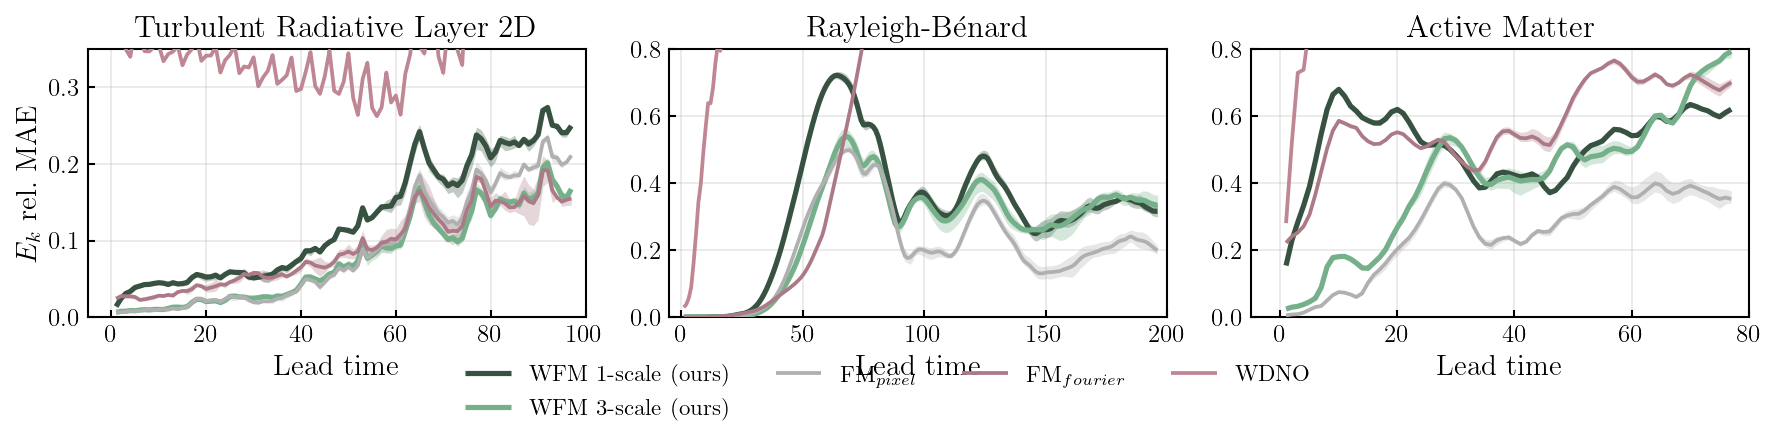

In [8]:
KE_YLIMS = {
    "turbulent_radiative_layer_2D": (0, 0.35),
    "rayleigh_benard":              (0, 0.80),
    "active_matter":                (0, 0.80),        # autoscale until you eyeball it
}

metric_to_plot = ("ke_mae_tm", r"$E_k$ rel.\ MAE", dict(logy=False))

gf = family_frame(g_phys)                      # ONE canonical key per (pde, family)

n_pdes = max(len(pde_present), 1)
fig, axs = plt.subplots(1, n_pdes, figsize=(min(4.2 * n_pdes, TEXT_WIDTH), ROW_HEIGHT), squeeze=False)

legend_families = []
for col, pde in enumerate(pde_present):
    fams = panel_families(pde)
    legend_families += fams

    metric, ylab, kw = metric_to_plot
    ax = axs[0][col]
    if metric not in gf.columns or gf.loc[gf.pde == pde, metric].isna().all():
        ax.set_visible(False)
        continue

    draw_metric(ax, gf, pde, metric, fams, mode="seed_avg", band_alpha=0.3, **kw)

    yl = KE_YLIMS.get(pde)
    if yl: ax.set_ylim(*yl)

    if col == 0:
        ax.set_ylabel(ylab, fontsize=14)
    ax.set_title(PDE_LABELS.get(pde, pde), fontsize=15, fontweight="bold")
    ax.set_xlabel("Lead time", fontsize=14)

add_legend(fig, set(legend_families), ncol=4, y=-0.08)
fig.tight_layout()
if SAVE_FIGS:
    fig.savefig(FIG_DIR / "figP1_physics_KE_relative_MAE.pdf", dpi=400, bbox_inches="tight", transparent=False)
plt.show()


# Enstrophy relative MAE

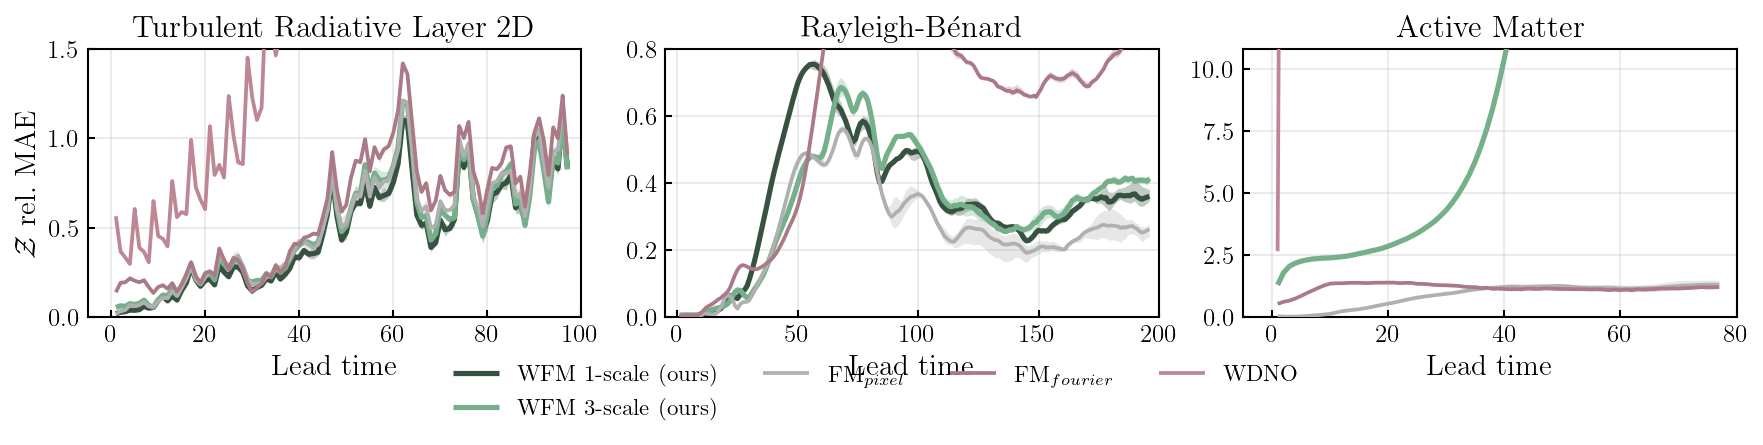

In [9]:
ENS_YLIMS = {
    "turbulent_radiative_layer_2D": (0, 1.50),
    "rayleigh_benard":              (0, 0.80),
    "active_matter":                (0, 10.80),        # autoscale until you eyeball it
}


metric_to_plot = ("enstrophy_mae_tm", r"$\mathcal{Z}$ rel.\ MAE", dict(logy=False))

gf = family_frame(g_phys)                      # ONE canonical key per (pde, family)

n_pdes = max(len(pde_present), 1)
fig, axs = plt.subplots(1, n_pdes, figsize=(min(4.2 * n_pdes, TEXT_WIDTH), ROW_HEIGHT), squeeze=False)

legend_families = []
for col, pde in enumerate(pde_present):
    fams = panel_families(pde)
    legend_families += fams

    metric, ylab, kw = metric_to_plot
    ax = axs[0][col]
    if metric not in gf.columns or gf.loc[gf.pde == pde, metric].isna().all():
        ax.set_visible(False)
        continue

    draw_metric(ax, gf, pde, metric, fams, mode="seed_avg", band_alpha=0.3, **kw)

    yl = ENS_YLIMS.get(pde)
    if yl: ax.set_ylim(*yl)

    if col == 0:
        ax.set_ylabel(ylab, fontsize=14)
    ax.set_title(PDE_LABELS.get(pde, pde), fontsize=15, fontweight="bold")
    ax.set_xlabel("Lead time", fontsize=14)

add_legend(fig, set(legend_families), ncol=4, y=-0.08)
fig.tight_layout()
if SAVE_FIGS:
    fig.savefig(FIG_DIR / "figP1_physics_enstrophy_relative_MAE.pdf", dpi=400, bbox_inches="tight", transparent=False)
plt.show()


# Summary table — mean $\pm$ sd across seeds, per lead-time horizon

Aggregation order: mean over (traj, steps-in-horizon) **within** each seed → mean $\pm$ sd **across** seeds. Model separation larger than the sd rules out sampling luck; this is the table where late-horizon columns separate models after pointwise metrics have saturated.

In [12]:
#SUMMARY_METRICS = ["ke_bias_tm", "enstrophy_bias_tm", "massflux_bias_tm", "nusselt_bias_tm", "nematic_bias_tm"] + CONS_CANDIDATES
#SUMMARY_METRICS = ["ke_mae_tm", "enstrophy_bias_tm", "massflux_bias_tm", "nusselt_bias_tm", "nematic_bias_tm"] + CONS_CANDIDATES
SUMMARY_METRICS = ["ke_mae_tm"]

PM_DISPLAY = "\u00b1"     # "±" for notebook display
PM_LATEX   = r"$\pm$"     # for .tex export only

def banded_summary(pde, pm=PM_DISPLAY):
    sub  = family_frame(g_phys)                 # ONE canonical key per (pde,family)
    sub  = sub[sub["pde"] == pde]
    cols = [c for c in SUMMARY_METRICS if c in sub.columns and sub[c].notna().any()]
    out  = {}
    for c in cols:
        per_seed = (sub.dropna(subset=[c])
                    .groupby(["family", "seed", "horizon"])[c].mean())
        st = per_seed.groupby(["family", "horizon"]).agg(["mean", "std", "count"])
        out[c] = st.apply(
            lambda r: f"{r['mean']:.3f}" + (f" {pm} {r['std']:.3f}"
                                            if r["count"] > 1 else ""), axis=1)
    if not out:
        return None
    tab = pd.concat(out, axis=1).unstack("horizon")
    tab = tab.reindex([f for f in family_order(list(FAMILY_REGISTRY)) if f in tab.index])
    tab.index = [fam_labels.get(f, f) for f in tab.index]
    return tab

for pde in pde_present:
    tab = banded_summary(pde)                    # display version: ±
    if tab is not None:
        print(f"\n===== {PDE_LABELS.get(pde, pde)} =====")
        try:
            from IPython.display import display
            display(tab)
        except Exception:
            print(tab.to_string())

# ── optional: LaTeX version for the paper ────────────────────────────────────
tab_tex = banded_summary(pde_present[0], pm=PM_LATEX)
print(tab_tex.to_latex(escape=False))          # escape=False keeps $\pm$ live


===== Turbulent Radiative Layer 2D =====


ke_mae_tm                              
horizon                     01:32          33:64          65:97
WFM 1-scale (ours)  0.047 ± 0.001  0.108 ± 0.001  0.221 ± 0.006
WFM 3-scale (ours)  0.017 ± 0.001  0.063 ± 0.003  0.147 ± 0.004
FM$_{pixel}$        0.016 ± 0.001  0.062 ± 0.004  0.176 ± 0.007
FM$_{fourier}$      0.037 ± 0.002  0.079 ± 0.004  0.150 ± 0.013
WDNO                0.346 ± 0.000  0.307 ± 0.001  0.478 ± 0.001


===== Rayleigh-Bénard =====


ke_mae_tm                              
horizon                     01:32          33:64         65:196
WFM 1-scale (ours)  0.006 ± 0.000  0.389 ± 0.005  0.382 ± 0.010
WFM 3-scale (ours)  0.002 ± 0.000  0.201 ± 0.005  0.349 ± 0.023
FM$_{pixel}$        0.003 ± 0.000  0.221 ± 0.005  0.253 ± 0.010
FM$_{fourier}$      0.006 ± 0.000  0.141 ± 0.001  1.014 ± 0.005
WDNO                0.798 ± 0.001  1.608 ± 0.004  1.745 ± 0.002


===== Active Matter =====


ke_mae_tm                              
horizon                     01:16          17:32          33:77
WFM 1-scale (ours)  0.497 ± 0.001  0.547 ± 0.005  0.507 ± 0.001
WFM 3-scale (ours)  0.109 ± 0.002  0.372 ± 0.012  0.530 ± 0.004
FM$_{pixel}$        0.046 ± 0.000  0.276 ± 0.012  0.320 ± 0.010
FM$_{fourier}$      0.434 ± 0.003  0.518 ± 0.001  0.637 ± 0.008
WDNO                0.879 ± 0.000  0.926 ± 0.001  0.934 ± 0.001

\begin{tabular}{llll}
\toprule
 & \multicolumn{3}{r}{ke_mae_tm} \\
horizon & 01:32 & 33:64 & 65:97 \\
\midrule
WFM 1-scale (ours) & 0.047 $\pm$ 0.001 & 0.108 $\pm$ 0.001 & 0.221 $\pm$ 0.006 \\
WFM 3-scale (ours) & 0.017 $\pm$ 0.001 & 0.063 $\pm$ 0.003 & 0.147 $\pm$ 0.004 \\
FM$_{pixel}$ & 0.016 $\pm$ 0.001 & 0.062 $\pm$ 0.004 & 0.176 $\pm$ 0.007 \\
FM$_{fourier}$ & 0.037 $\pm$ 0.002 & 0.079 $\pm$ 0.004 & 0.150 $\pm$ 0.013 \\
WDNO & 0.346 $\pm$ 0.000 & 0.307 $\pm$ 0.001 & 0.478 $\pm$ 0.001 \\
\bottomrule
\end{tabular}



In [13]:
# ═════════════════════════════════════════════════════════════════════════════
# Single-metric summary table
#   columns : PDE (top level)  ->  rollout horizon (sub level)
#   rows    : model
#   cells   : mean ± std across seeds   (best bold, 2nd best underlined)
# ═════════════════════════════════════════════════════════════════════════════

SELECTED_METRIC   = "ke_mae_tm"   # the ONE metric to report
#SELECTED_METRIC   = "enstrophy_mae_tm"   # the ONE metric to report
LOWER_IS_BETTER   = True                  # bias / mae / conservation -> True

try:
    HORIZON_ORDER
except NameError:
    HORIZON_ORDER = list(pd.unique(g_phys["horizon"]))


def _metric_stats(metric):
    """One row per (pde, model, horizon): average each seed's frames first,
    then mean / std / count ACROSS seeds -- so std is seed-to-seed variability,
    matching the two-stage groupby in your original."""
    frames = []
    gf = family_frame(g_phys)                 # ONE canonical key per (pde, family)
    for pde in pde_present:
        sub = gf[gf["pde"] == pde]
        if metric not in sub.columns or not sub[metric].notna().any():
            continue
        # guard: after family_frame, each (family,seed,horizon) is a single key
        dup = sub.groupby("family")["model"].nunique()
        assert (dup <= 1).all(), f"{pde}: family maps to >1 key {dict(dup[dup>1])}"
        per_seed = (sub.dropna(subset=[metric])
                       .groupby(["family", "seed", "horizon"])[metric].mean())
        st = (per_seed.groupby(["family", "horizon"])
                      .agg(["mean", "std", "count"]).reset_index())
        st["pde"] = pde
        frames.append(st)
    return pd.concat(frames, ignore_index=True) if frames else None


def metric_table(metric=SELECTED_METRIC, pm=PM_DISPLAY, latex=False,
                 lower_is_better=LOWER_IS_BETTER):
    """Returns (display_object, mean_frame).
    latex=False -> a Styler (bold best, underline 2nd) for the notebook.
    latex=True  -> a string DataFrame with \\textbf / \\underline for .to_latex."""
    stats = _metric_stats(metric)
    if stats is None:
        return None, None

    stats["horizon"] = pd.Categorical(stats["horizon"],
                                      categories=HORIZON_ORDER, ordered=True)

    mean_f = stats.pivot_table(index="family", columns=["pde", "horizon"],
                               values="mean", observed=True)

    def _fmt(row):
        if pd.isna(row["mean"]):
            return ""
        s = f"{row['mean']:.3f}"
        if row["count"] > 1 and pd.notna(row["std"]):
            s += f" {pm} {row['std']:.3f}"
        return s
    stats["cell"] = stats.apply(_fmt, axis=1)
    disp_f = stats.pivot_table(index="family", columns=["pde", "horizon"],
                               values="cell", aggfunc="first", observed=True)

    col_order = [(p, h) for p in pde_present for h in HORIZON_ORDER
                 if (p, h) in mean_f.columns]
    mean_f = mean_f.reindex(columns=pd.MultiIndex.from_tuples(col_order))
    disp_f = disp_f.reindex(columns=mean_f.columns)

    row_order = [f for f in family_order(list(FAMILY_REGISTRY)) if f in mean_f.index] + \
                [f for f in mean_f.index if f not in FAMILY_REGISTRY]
    mean_f = mean_f.reindex(row_order)
    disp_f = disp_f.reindex(row_order)
    pretty_rows = [fam_labels.get(f, f) for f in mean_f.index]

    rank_f = mean_f.rank(axis=0, method="min", ascending=lower_is_better)

    if latex:
        out = disp_f.copy()
        for c in out.columns:
            for i in out.index:
                if disp_f.at[i, c] == "" or pd.isna(disp_f.at[i, c]):
                    out.at[i, c] = "--"
                    continue
                r = rank_f.at[i, c]
                if r == 1:
                    out.at[i, c] = r"\textbf{" + disp_f.at[i, c] + "}"
                elif r == 2:
                    out.at[i, c] = r"\underline{" + disp_f.at[i, c] + "}"
        out.index = pretty_rows
        out.columns = pd.MultiIndex.from_tuples(
            [(PDE_LABELS.get(p, p), h) for p, h in out.columns],
            names=["PDE", "horizon"])
        return out, mean_f

    disp_show = disp_f.fillna("").replace("", "—").copy()
    disp_show.index = pretty_rows
    disp_show.columns = pd.MultiIndex.from_tuples(
        [(PDE_LABELS.get(p, p), h) for p, h in disp_f.columns],
        names=["PDE", "horizon"])

    rank_arr = rank_f.to_numpy()

    def _style(_):
        css = np.full(rank_arr.shape, "", dtype=object)
        css[rank_arr == 1] = "font-weight:bold;"
        css[rank_arr == 2] = "text-decoration:underline;"
        return pd.DataFrame(css, index=disp_show.index, columns=disp_show.columns)

    styler = (disp_show.style.apply(_style, axis=None)
              .set_caption(f"{metric} — mean {pm} std over seeds "
                           f"({'lower' if lower_is_better else 'higher'} is better; "
                           f"bold = best, underline = 2nd)"))
    return styler, mean_f


# ── display ──────────────────────────────────────────────────────────────────
styler, mean_f = metric_table(SELECTED_METRIC)
if styler is None:
    print(f"'{SELECTED_METRIC}' not present for any PDE.")
else:
    from IPython.display import display
    display(styler)